<a href="https://colab.research.google.com/github/sgterrado/Need4Data-Blue-Bumper-Cars/blob/Ann%2FData-clean/Need4Data_DataClean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Cleaning

**Leading question:**

How does weather and time of day affect car accidents?

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.pyplot as plt
import missingno as msno

In [5]:
#Removes Science Notation from df.describe() and other functions
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

In [6]:
df = pd.read_csv('US_Accidents_March23_sampled_500k.csv', encoding ='latin1')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  str    
 1   Source                 500000 non-null  str    
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  str    
 4   End_Time               500000 non-null  str    
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  str    
 11  Street                 499309 non-null  str    
 12  City                   499981 non-null  str    
 13  County                 500000 non-null  str    
 14  State                  500000 non-null  str    

In [8]:
#Check for duplicates
df[df.duplicated()]

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight


There is no duplicate to drop.

In [9]:
#check for n/a rate
s = df.isna().mean()*100
s[s>0]


End_Lat                 44.08
End_Lng                 44.08
Description              0.00
Street                   0.14
City                     0.00
Zipcode                  0.02
Timezone                 0.10
Airport_Code             0.29
Weather_Timestamp        1.53
Temperature(F)           2.09
Wind_Chill(F)           25.80
Humidity(%)              2.23
Pressure(in)             1.79
Visibility(mi)           2.26
Wind_Direction           2.24
Wind_Speed(mph)          7.40
Precipitation(in)       28.52
Weather_Condition        2.22
Sunrise_Sunset           0.30
Civil_Twilight           0.30
Nautical_Twilight        0.30
Astronomical_Twilight    0.30
dtype: float64

Most concerning column with missing data would be `End_lat` and `End_lng` for having more than 44% of missing value. For the dataset I will drop `End_lat` and `Eng_lng` for the alarming high amount of missing values and their not being able to contribute to our team leading question "How does weather and time of day affect car accidents?" I will also drop column ID for it is just an indentifier and doesn't give useful infomation.
Base on our team leading question  **how weather and time of day affet traffic?**, I will also drop the column that will not give us useful weather infomation : `Start_Lat, Start_lng, Source, Description,Street, Airport_Code, Bump, Crossing, Give_Way, Junction, Railway, Roundabout, Stop, Traffic_Calming, Traffic_Signal, Turning_Loop, Amenity, Weather_Timestamp`

In [10]:
#Drop columns with too many NaN values and ID
df = df.drop(columns = ['End_Time', 'End_Lat', 'End_Lng', 'ID', 'Start_Lat', 'Start_Lng', 'Description', 'Street',
                        'Airport_Code', 'Bump', 'Crossing', 'Give_Way',
                        'Junction', 'No_Exit', 'Railway', 'Roundabout',
                        'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
                        'Turning_Loop', 'Amenity', 'Source', 'Weather_Timestamp'])

Now I need to identify potential incorrect data type and fix them.

In [11]:
df['Country'].unique()

<ArrowStringArray>
['US']
Length: 1, dtype: str

I will drop `Timezone` and `Country` for all the entry in the dataset is set in the US and `Start_Time` and `End_Time` are recorded in local time.

In [12]:
df = df.drop(columns= ['Timezone', 'Country'])

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Severity               500000 non-null  int64  
 1   Start_Time             500000 non-null  str    
 2   Distance(mi)           500000 non-null  float64
 3   City                   499981 non-null  str    
 4   County                 500000 non-null  str    
 5   State                  500000 non-null  str    
 6   Zipcode                499884 non-null  str    
 7   Temperature(F)         489534 non-null  float64
 8   Wind_Chill(F)          370983 non-null  float64
 9   Humidity(%)            488870 non-null  float64
 10  Pressure(in)           491072 non-null  float64
 11  Visibility(mi)         488709 non-null  float64
 12  Wind_Direction         488803 non-null  str    
 13  Wind_Speed(mph)        463013 non-null  float64
 14  Precipitation(in)      357384 non-null  float64

We only need 1 daytime/nightime identifier from `Sunrise_Sunset, Civil_Twilight, Astronomical_Twilight, Nautical_Twilight`




In [14]:
#find which will be the most optimal day/night identifier
df['Sunrise_Sunset'].isna().equals(df['Civil_Twilight'].isna()) and \
df['Sunrise_Sunset'].isna().equals(df['Nautical_Twilight'].isna()) and \
df['Sunrise_Sunset'].isna().equals(df['Astronomical_Twilight'].isna())



True

Since `Sunrise_Sunset, Civil_Twilight, Astronomical_Twilight, Nautical_Twilight` share the shame missing value pattern, I will keep the most understandable one which is the `Sunrise_Sunset`. And since the missing value rate in small (0.30%) I will drop those rows.

In [15]:
df = df.drop( columns= ['Civil_Twilight', 'Astronomical_Twilight',
                        'Nautical_Twilight'])

df.dropna(subset =['Sunrise_Sunset'], inplace = True)

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 498517 entries, 0 to 499999
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Severity           498517 non-null  int64  
 1   Start_Time         498517 non-null  str    
 2   Distance(mi)       498517 non-null  float64
 3   City               498517 non-null  str    
 4   County             498517 non-null  str    
 5   State              498517 non-null  str    
 6   Zipcode            498402 non-null  str    
 7   Temperature(F)     488221 non-null  float64
 8   Wind_Chill(F)      369686 non-null  float64
 9   Humidity(%)        487561 non-null  float64
 10  Pressure(in)       489757 non-null  float64
 11  Visibility(mi)     487398 non-null  float64
 12  Wind_Direction     487496 non-null  str    
 13  Wind_Speed(mph)    461707 non-null  float64
 14  Precipitation(in)  356075 non-null  float64
 15  Weather_Condition  487587 non-null  str    
 16  Sunrise_Sunset    

We only need 1 Temperature measure so I will keep Temperature(F) and drop Wind_Chill(F) for it has high missing value rate.

In [17]:
df = df.drop( columns= ['Wind_Chill(F)'])

In [18]:
df.head(5)

,Severity,Start_Time,Distance(mi),City,County,State,Zipcode,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Sunrise_Sunset
0,2,2019-06-12 10:10:56,0.00,Zachary,East Baton Rouge,LA,70791-4610,77.00,62.00,29.92,10.00,NW,5.00,0.00,Fair,Day
1,2,2022-12-03 23:37:14.000000000,0.06,Sterling,Loudoun,VA,20164-2813,45.00,48.00,29.91,10.00,W,5.00,0.00,Fair,Night
2,2,2022-08-20 13:13:00.000000000,0.02,Lompoc,Santa Barbara,CA,93436,68.00,73.00,29.79,10.00,W,13.00,0.00,Fair,Day
3,2,2022-02-21 17:43:04,1.05,Austin,Mower,MN,55912,27.00,86.00,28.49,10.00,ENE,15.00,0.00,Wintry Mix,Day
4,2,2020-12-04 01:46:00,0.05,Bakersfield,Kern,CA,93305-2649,42.00,34.00,29.77,10.00,CALM,0.00,0.00,Fair,Night


 Found mismatch `Start_Time, Zipcode` layout, fixing that first


In [19]:
df['Start_Time'] = pd.to_datetime(
    df['Start_Time'],
    errors = 'coerce',
    format = 'mixed'
)


In [20]:
df.loc[~df['Zipcode'].astype(str).str.match(r'^\d{5}(-\d{4})?$', na=False)]['Zipcode'].unique()

<ArrowStringArray>
['93247-94ND', '91105-18ND', '30518-17ND',          nan, '93210-97ND',
 '44039-40ND', '91214-28ND', '44105-56ND', '44104-27ND', '30336-15ND',
 ...
 '93307-31ND', '23220-54ND', '30510-38ND', '23607-26ND', '93301-48ND',
 '29532-86ND', '32081-84ND', '30360-31ND', '34210-28ND', '90221-54ND']
Length: 196, dtype: str

In [21]:
df['Zipcode'] = df['Zipcode'].astype(str).str[:5] #stip to get 5 zip standard

df['Zipcode'].value_counts(dropna = False)

Zipcode
27610    846
32819    788
33186    745
91761    739
70808    716
        ... 
31309      1
32346      1
88318      1
05743      1
84408      1
Name: count, Length: 16592, dtype: int64

In [22]:
df['Severity'].unique() # Nothing wrong here

array([2, 3, 4, 1])

In [23]:
df['State'].unique() # Nothing wrong here

<ArrowStringArray>
['LA', 'VA', 'CA', 'MN', 'MA', 'OR', 'FL', 'TX', 'IN', 'MT', 'AL', 'AZ', 'NY',
 'NC', 'SC', 'KS', 'MI', 'CO', 'GA', 'MD', 'IL', 'PA', 'NM', 'NV', 'NE', 'NJ',
 'TN', 'UT', 'RI', 'MS', 'IA', 'WA', 'MO', 'OH', 'OK', 'CT', 'DC', 'AR', 'WV',
 'KY', 'WI', 'NH', 'WY', 'DE', 'VT', 'ID', 'ME', 'ND', 'SD']
Length: 49, dtype: str

In [24]:
df['Weather_Condition'].unique()

<ArrowStringArray>
[                        'Fair',                   'Wintry Mix',
                   'Light Rain',                       'Cloudy',
                'Mostly Cloudy',                'Partly Cloudy',
                        'Clear',             'Scattered Clouds',
                          'Fog',                     'Overcast',
 ...
    'Light Rain Shower / Windy', 'Light Thunderstorms and Snow',
            'Light Snow Grains',             'Thunder and Hail',
        'Drifting Snow / Windy',                 'Volcanic Ash',
                 'Mist / Windy',           'Light Blowing Snow',
            'Low Drifting Snow',                         'Sand']
Length: 109, dtype: str

The `Weather_Condition` has too many catergories but all contain important weather information that cannot be combined. Because a thunderstorm snow is not just thunder nor just snow, so I will split the columns into `boolean` types of `|clear|rain|ice|windy|thunder|cloudy|smoke/dust|snow|` and then drop `Weather_Condition`

* squalls : a sudden increase in wind speed, might be accompanied by rain, storm, snow
* wintry mix : a rapid combination winter precipitation, such as snow, freezing rain and sleet







In [25]:
df['Weather_Condition'] = df['Weather_Condition'].replace('N/A Precipitation','')
df['Weather_Condition'] = df['Weather_Condition'].str.lower()

df['Clear_Weather'] = df['Weather_Condition'].str.contains('fair|clear')
df['Rain'] = df['Weather_Condition'].str.contains('rain|drizzle|shower')
df['Ice'] = df['Weather_Condition'].str.contains('freezing|hail|wintry|sleet|ice|pellet')
df['Windy'] = df['Weather_Condition'].str.contains('funnel|tornado|windy|whirlwind|squall')
df['Thunder'] = df['Weather_Condition'].str.contains('thunder|storm')
df['Cloudy'] = df['Weather_Condition'].str.contains('overcast|funnel|cloudy')
df['Smoke/Dust'] = df['Weather_Condition'].str.contains('smoke|sand|dust|haze|fog|ash|mist')
df['Snow'] = df['Weather_Condition'].str.contains('wintry|snow')

df.info()

<class 'pandas.DataFrame'>
Index: 498517 entries, 0 to 499999
Data columns (total 24 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   Severity           498517 non-null  int64         
 1   Start_Time         498517 non-null  datetime64[ns]
 2   Distance(mi)       498517 non-null  float64       
 3   City               498517 non-null  str           
 4   County             498517 non-null  str           
 5   State              498517 non-null  str           
 6   Zipcode            498402 non-null  str           
 7   Temperature(F)     488221 non-null  float64       
 8   Humidity(%)        487561 non-null  float64       
 9   Pressure(in)       489757 non-null  float64       
 10  Visibility(mi)     487398 non-null  float64       
 11  Wind_Direction     487496 non-null  str           
 12  Wind_Speed(mph)    461707 non-null  float64       
 13  Precipitation(in)  356075 non-null  float64       
 14  Weat

<Axes: >

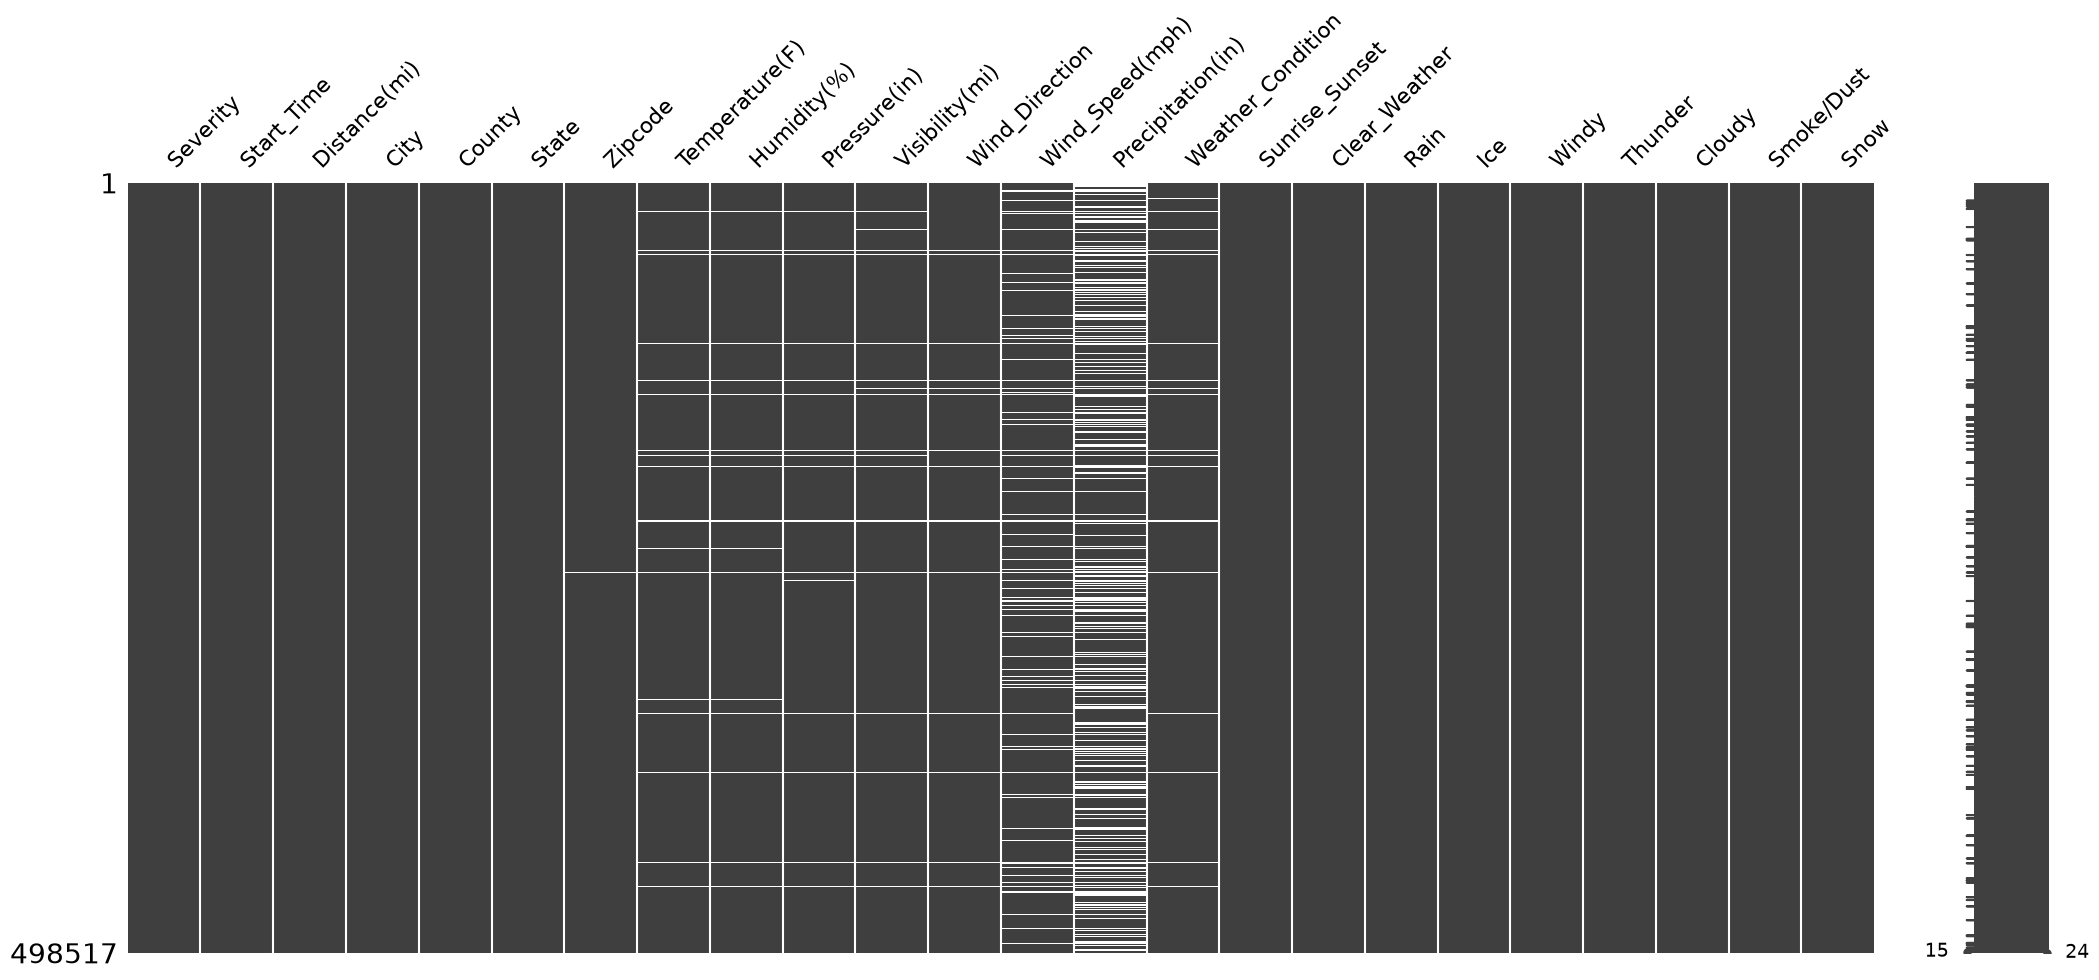

In [26]:
msno.matrix(df)

Because of `Weather_Condition` has NaN value, all the new tag will also show NaN at those specific entry.
Looking at the visualization, `Temperature(F), Wind_Chill(F),Humidity(%), Pressure, Visibility, Wind_direction, Wind_Speed, Precipitation(in), Weather_Condition` and all the new tags have a similar pattern on missing value (the straight line across). I will confirm this and drop those entry if they exist becasue weather infomation is unknown for those accident.

In [27]:
cols_to_check = ['Temperature(F)','Humidity(%)','Pressure(in)',
                 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)',
                 'Precipitation(in)', 'Weather_Condition']

df[cols_to_check].isna().all(axis=1).mean() * 100 # check how much they exist in the dataset

np.float64(1.5074711594589552)

<Axes: >

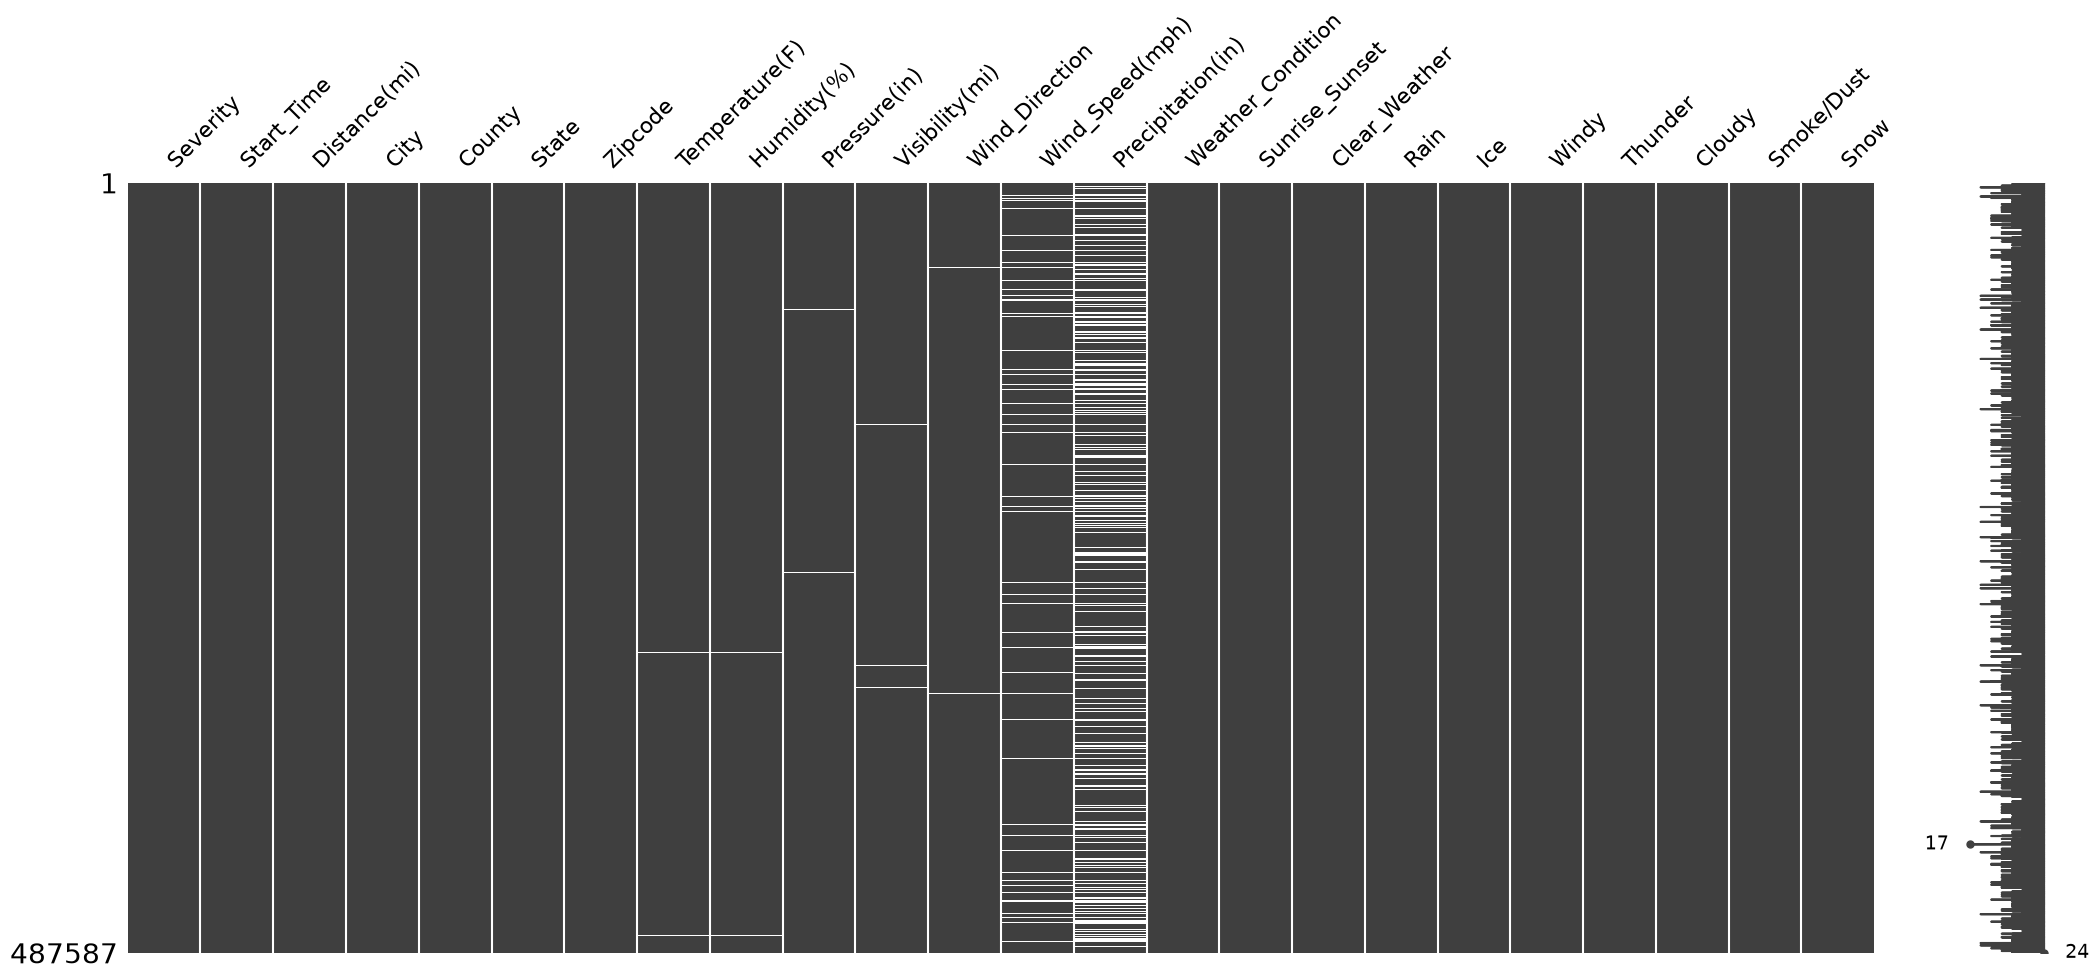

In [28]:
df = df.dropna(subset=['Temperature(F)','Humidity(%)','Pressure(in)',
                 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)',
                 'Precipitation(in)', 'Weather_Condition'], how= 'all')

#drop NaN weather condition because we need the weather data
df.dropna(subset =['Weather_Condition'], inplace = True)

msno.matrix(df)


In [29]:
s = df.isna().mean()*100
s[s>0]

Temperature(F)       0.36
Humidity(%)          0.49
Pressure(in)         0.12
Visibility(mi)       0.27
Wind_Direction       0.53
Wind_Speed(mph)      5.60
Precipitation(in)   27.35
dtype: float64

In [30]:
df['Wind_Direction'].unique()

<ArrowStringArray>
[      'NW',        'W',      'ENE',     'CALM',       'SW',      'VAR',
        'S',        'E',      'WSW',      'NNE', 'Variable',     'West',
        'N',      'ESE',      'NNW',    'North',      'SSW',      'WNW',
       'NE',     'Calm',       'SE',     'East',      'SSE',    'South',
        nan]
Length: 25, dtype: str

In [31]:
df['Wind_Direction'] = df['Wind_Direction'].replace({
    "North" : "N",
    "East" : "E",
    "South" : "S",
    "Calm" : "CALM",
    "West" : "W",
    "Variable" : "VAR"
})

In [32]:
df['Wind_Direction'] = df['Wind_Direction'].fillna("Unknown")

In [33]:
df['Wind_Direction'].value_counts(dropna=False)

Wind_Direction
CALM       85715
S          38319
W          35482
N          28723
SSW        24641
E          24411
WNW        24192
NW         23761
SW         23536
VAR        23466
WSW        22749
SSE        22533
NNW        21425
SE         19062
ESE        17097
NE         16766
ENE        16606
NNE        16536
Unknown     2567
Name: count, dtype: int64

In [34]:
df['Temperature(F)'].describe()

count   485853.00
mean        61.66
std         18.99
min        -35.00
25%         49.00
50%         64.00
75%         76.00
max        207.00
Name: Temperature(F), dtype: float64

IQR = 27, Upper Bound = Q3 +1.5IQR = 116.5 meaning any value > 116 is an outlier, such as 207
But there is places in the US that can have outdoor temperature up to 130°F so I will check and possibly remove base on that rather than using the upper bound. -35 is a reasonable temperature because someplace can reach -70°F
I will also replace NaN with median value to not affect the data much.

In [35]:
df[df['Temperature(F)'] > 120]['Temperature(F)']

63069    140.00
193548   207.00
426439   196.00
Name: Temperature(F), dtype: float64

In [36]:
df = df[df['Temperature(F)'] <=120] #drop the temperature outside 130°F
df['Temperature(F)'] = df['Temperature(F)'].fillna(df['Temperature(F)'].median())
df['Temperature(F)'].describe()

count   485850.00
mean        61.66
std         18.98
min        -35.00
25%         49.00
50%         64.00
75%         76.00
max        117.00
Name: Temperature(F), dtype: float64

`Precipitation(in)` has a high rate of missing value, assuming if the weather was clear/fair then `Precipitation(in)` should have been zero.
But if the weather tags for Rain, Snow then it should not be zero.

In [37]:
df['Precipitation(in)'].describe()

count   353037.00
mean         0.01
std          0.10
min          0.00
25%          0.00
50%          0.00
75%          0.00
max         10.09
Name: Precipitation(in), dtype: float64

In [38]:
df[df['Clear_Weather']]['Precipitation(in)'].isna().mean()*100

np.float64(26.24008026999909)

In [39]:
df[df['Cloudy']]['Precipitation(in)'].isna().mean()*100

np.float64(29.760716799193286)

In [40]:
df[df['Rain']]['Precipitation(in)'].isna().mean()*100

np.float64(5.211848518935133)

In [41]:
df[df['Smoke/Dust']]['Precipitation(in)'].isna().mean()*100

np.float64(25.466880097568414)

In [42]:
df[df['Snow']]['Precipitation(in)'].isna().mean()*100

np.float64(4.898108379786165)

In [43]:
df[df['Thunder']]['Precipitation(in)'].isna().mean()*100

np.float64(5.697653907214676)

In [44]:
df[df['Ice']]['Precipitation(in)'].isna().mean()*100

np.float64(6.240369799691833)

Examining the missing rate vs. the weather tags, it show that when `Rain`, `Snow`, `Thunder` or `Ice` is `True`, they are more likely to have a value. And when `Clear_Wheather, Cloudy` or `Smoke/Dust` it is more likely to NaN. I believe this show a pattern that NaN value is actually "no measuareble precipitation" recorded when it is not raining, snowing and in a storm. But because 75% of Precipitation is 0.0. indicating that these are the case of when precipitation cannot be measured. I will just leave the Precipitation as is and not replace all with 0.0.

In [45]:
s = df.isna().mean()*100
s[s>0]

Humidity(%)          0.13
Pressure(in)         0.09
Visibility(mi)       0.25
Wind_Speed(mph)      5.55
Precipitation(in)   27.34
dtype: float64

In [46]:
df['Humidity(%)'].describe()

count   485198.00
mean        64.83
std         22.82
min          1.00
25%         48.00
50%         67.00
75%         84.00
max        100.00
Name: Humidity(%), dtype: float64

Humidity is in reasonable range so I will deal with the NaN

In [47]:
df['Humidity(%)'] = df['Humidity(%)'].fillna(df['Humidity(%)'].median())

In [48]:
df['Pressure(in)'].describe()

count   485409.00
mean        29.54
std          1.00
min          2.99
25%         29.37
50%         29.86
75%         30.03
max         38.44
Name: Pressure(in), dtype: float64

The highest record of air pressure in the US was 31.85in and lowest is 26.35 so a max of 38.44 and a min of 2.99 is definitely an invalid entry.

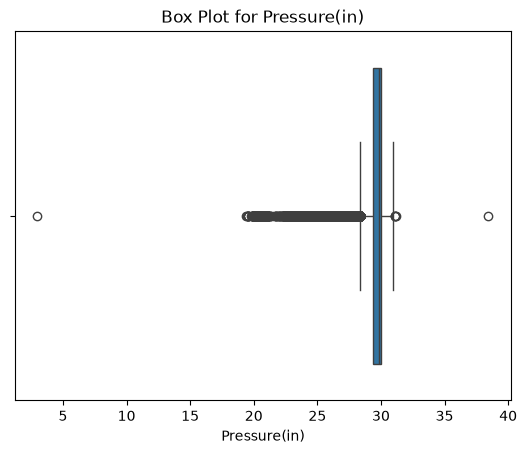

In [49]:
sns.boxplot(x=df['Pressure(in)'])
plt.title("Box Plot for Pressure(in)")
plt.show()

In [50]:
# check value outside of plausible range
print("Missing rate", ((df['Pressure(in)'] < 26.35) | (df['Pressure(in)'] > 32)).mean()*100)
print("Total of entry ", (((df['Pressure(in)'] < 26.35) | (df['Pressure(in)'] > 32)).sum()))

Missing rate 2.977873829371205
Total of entry  14468


Since there are too many out of range value of pressure and might not have too much impact on the weather data, I will convert all to NaN. If we need complete data, compute later.

In [51]:
df.loc[((df['Pressure(in)'] < 26.35) | (df['Pressure(in)'] > 32)), 'Pressure(in)'] = np.nan

In [52]:
df['Wind_Speed(mph)'].describe()

count   458870.00
mean         7.68
std          5.43
min          0.00
25%          4.60
50%          7.00
75%         10.40
max        822.80
Name: Wind_Speed(mph), dtype: float64

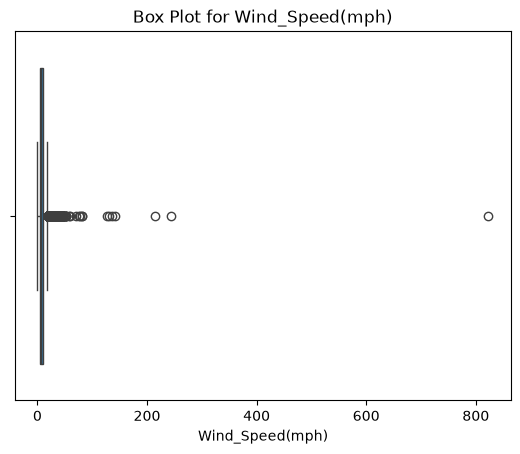

In [53]:
sns.boxplot(x=df['Wind_Speed(mph)'])
plt.title("Box Plot for Wind_Speed(mph)")
plt.show()

In [54]:
df[df['Wind_Speed(mph)']>321] #highest wind ever detected is 321mph

,Severity,Start_Time,Distance(mi),City,County,State,Zipcode,Temperature(F),Humidity(%),Pressure(in),...,Weather_Condition,Sunrise_Sunset,Clear_Weather,Rain,Ice,Windy,Thunder,Cloudy,Smoke/Dust,Snow
371110,3,2016-06-13 20:06:45,0.00,Pacoima,Los Angeles,CA,91331,71.60,53.00,30.06,...,clear,Night,True,False,False,False,False,False,False,False


In [55]:
df.loc[(df['Wind_Speed(mph)']>321), 'Wind_Speed(mph)'] = np.nan

In [56]:
df['Visibility(mi)'].describe()

count   484613.00
mean         9.09
std          2.70
min          0.00
25%         10.00
50%         10.00
75%         10.00
max        130.00
Name: Visibility(mi), dtype: float64

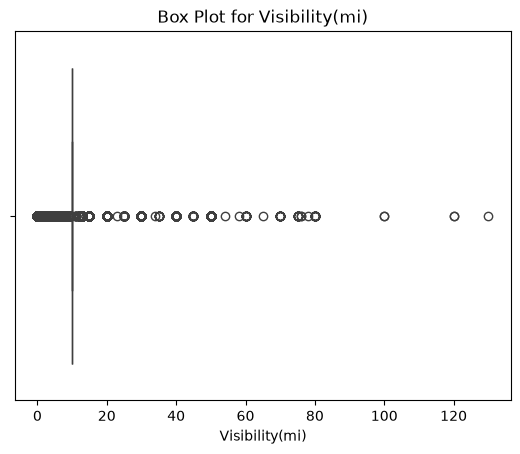

In [57]:
sns.boxplot(x=df['Visibility(mi)'])
plt.title("Box Plot for Visibility(mi)")
plt.show()

Since 75% of Visibility are 10, I suspect this to be the weather station visibility report ceiling. I will cap any thing above 100 at 10 because it could be a entry error. For any value >10 and <100 I will leave it as is. Missing value would be replace with 10 as it will not impact tthe overal pattern in the Visibility(mi).

In [58]:
df.loc[df['Visibility(mi)']>=100,'Visibility(mi)'] = 10
df['Visibility(mi)'] = df['Visibility(mi)'].fillna(10)

In [59]:
s = df.isna().mean()*100
s[s>0]

Pressure(in)         3.07
Wind_Speed(mph)      5.55
Precipitation(in)   27.34
dtype: float64

For easier visualization I will separate the `Start_Time` into separate entities.

In [60]:
df['Month'] = df['Start_Time'].dt.month
df['Date'] = df['Start_Time'].dt.day
df['Year'] = df['Start_Time'].dt.year
df['Time_Hour'] = df['Start_Time'].dt.hour
df['Time_Minute'] = df['Start_Time'].dt.minute


#df = df.drop(columns= 'Start_Time')

df.head(5)

,Severity,Start_Time,Distance(mi),City,County,State,Zipcode,Temperature(F),Humidity(%),Pressure(in),...,Windy,Thunder,Cloudy,Smoke/Dust,Snow,Month,Date,Year,Time_Hour,Time_Minute
0,2,2019-06-12 10:10:56,0.00,Zachary,East Baton Rouge,LA,70791,77.00,62.00,29.92,...,False,False,False,False,False,6,12,2019,10,10
1,2,2022-12-03 23:37:14,0.06,Sterling,Loudoun,VA,20164,45.00,48.00,29.91,...,False,False,False,False,False,12,3,2022,23,37
2,2,2022-08-20 13:13:00,0.02,Lompoc,Santa Barbara,CA,93436,68.00,73.00,29.79,...,False,False,False,False,False,8,20,2022,13,13
3,2,2022-02-21 17:43:04,1.05,Austin,Mower,MN,55912,27.00,86.00,28.49,...,False,False,False,False,True,2,21,2022,17,43
4,2,2020-12-04 01:46:00,0.05,Bakersfield,Kern,CA,93305,42.00,34.00,29.77,...,False,False,False,False,False,12,4,2020,1,46


The visualizations below were made to explore the relationship between time and car accidents.

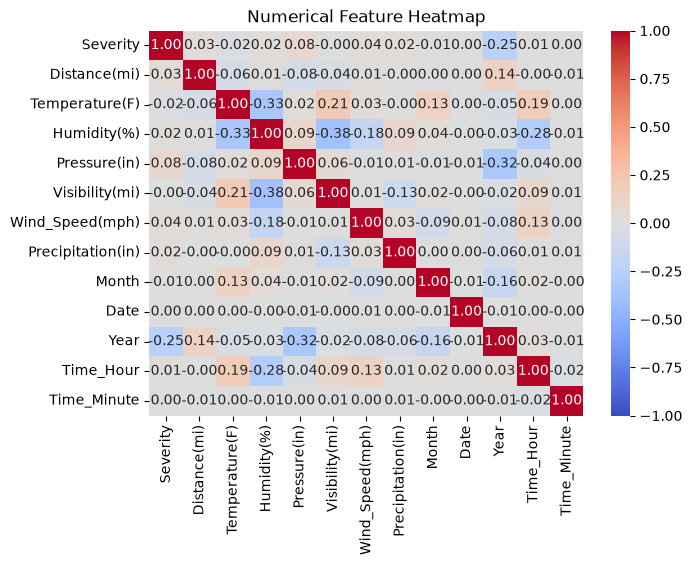

In [77]:
plt.figure(figsize=(7,5))
num_cols = df.select_dtypes(include=["number"])
sns.heatmap(num_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Numerical Feature Heatmap")
plt.show()

<Axes: title={'center': 'Accident Count by the Hour'}, xlabel='Hour', ylabel='Count'>

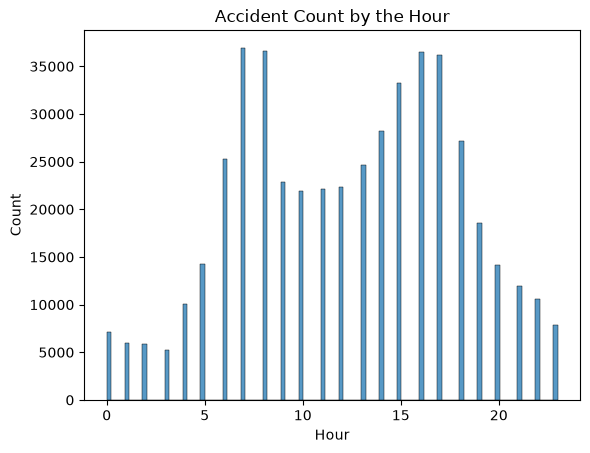

In [122]:
plt.title("Accident Count by the Hour")
plt.xlabel("Hour")

sns.histplot(data=df, x=df['Time_Hour'])

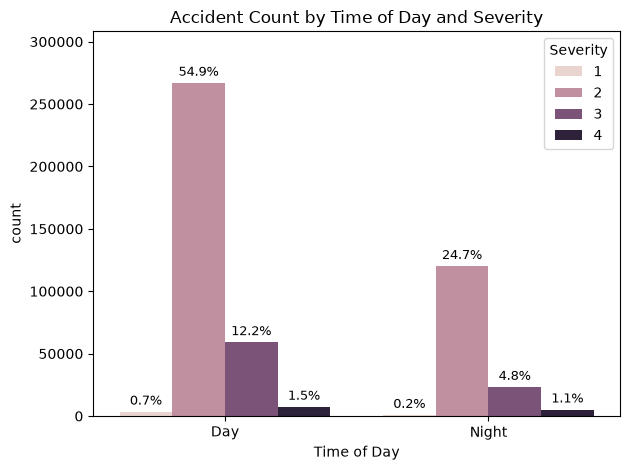

In [119]:
plt.title("Accident Count by Time of Day and Severity")
plt.xlabel("Time of Day")

ax = sns.countplot(data=df, x="Sunrise_Sunset", hue="Severity")

total = len(df)

for bar in ax.patches:
    count = bar.get_height()

    if count > 0:
        percentage = (count / total * 100)

        ax.annotate(
            f"{percentage:.1f}%",
            (bar.get_x() + bar.get_width() / 2, count),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points",
            fontsize=9
        )

ax.set_ylim(top=ax.get_ylim()[1] * 1.1)
plt.tight_layout()
plt.show()

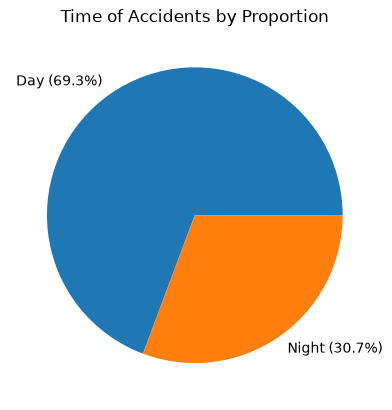

In [121]:
plt.title("Time of Accidents by Proportion")
day_count = df['Sunrise_Sunset'].value_counts().get('Day', 0) # 336691
night_count = df['Sunrise_Sunset'].value_counts().get('Night', 0) # 149159
total = [day_count, night_count] # 485850

labels = ["Day (69.3%)", "Night (30.7%)"]
plt.pie(total,labels=labels)
